In [1]:
using QuantumCollocation
using NamedTrajectories
using TrajectoryIndexingUtils

using CairoMakie
using DelimitedFiles
using Distributions
using LinearAlgebra

using ForwardDiff
using JLD2

In [2]:
# Operators 
const n_levels = 2
a⁺ = create(n_levels)
a⁻ = annihilate(n_levels)

const H_ops = Dict(
        "X" => a⁻ + a⁺,
        "Y" => -im * (a⁻ - a⁺),
        "Z" => I - 2 * a⁺ * a⁻,
)

# Time
T = 120
Δt = 0.5
times = range(0, T * Δt, length=T+1)[1:end]

0.0:0.5:60.0

In [3]:
function flat_gaussian(t::Real; area::Real=1.0, width::Real=0.0, T::Real=1.0, Δt::Real=1.0)
    """
    A flat top Gaussian pulse with zero amplitude at the end points t = 0 and t = T.

    Parameters
    ----------
    t : float
        Time

    Keyword Arguments
    -----------------
    area : float
        The integrated area of the pulse
    width : float
        Width ratio of the pulse top, (T - 2 * rise/fall time) / duration / Δt (default: 0.0)
    T : float
        Duration of the pulse in steps (default: 1.0)
    Δt : float
        Time step (default: 1.0)

    Returns
    -------
    float
        Value of the pulse at time t
    """
    @assert 0 <= width <= 1.0 "Width ratio must be between 0 and 1"
    
    # Duration of the pulse includes the final endpoint (alternative: (T - 1) * Δt)
    interval = T * Δt
    τ = t / interval
    a = area / interval

    if width ≈ 1.0
        if 0 <= τ <= 1
            return a
        else
            return 0.0
        end
    else
        if 0 <= τ < (1 - width) / 2
            return a / (1 + width) * (1 + cos((2 * π) /(1 - width) * (τ - (1 - width) / 2)))
        elseif (1 - width) / 2 <= τ < (1 + width)/2
            return 2 * a / (1 + width)
        elseif (1 + width) / 2 <= τ <= 1
            return a / (1 + width) * (1 + cos((2 * π) / (1 - width) * (τ - (1 + width) / 2)))
        else
            return 0.0
        end
    end
end

flat_gaussian (generic function with 1 method)

Curvature
\begin{equation}
    \kappa(t) = \frac{{|f''(t)|}}{{(1 + (f'(t))^2)^{\frac{3}{2}}}}
\end{equation}

In [4]:
function trapezoid_rule(y::AbstractArray; dx::Real=1.0)
    n = length(y)
    integral = (y[1] + y[n]) / 2.0
    for i in 2:n-1
        integral += y[i]
    end
    return integral * dx
end


function compute_derivatives(curve::Function, times::AbstractArray)
    ḟ(x) = ForwardDiff.derivative(curve, x)
    f̈(x) = ForwardDiff.derivative(ḟ, x)
    return Dict(
        :a => curve.(times),
        :da => ḟ.(times),
        :dda => f̈.(times)
    )
end


function curvature(curve::Function, t::Real)
    ḟ(x) = ForwardDiff.derivative(curve, x)
    ḟ_t = ḟ(t)
    f̈_t = ForwardDiff.derivative(ḟ, t)
    return abs(f̈_t) / (1 + ḟ_t^2)^(3/2)
end

curvature (generic function with 1 method)

In [5]:
# Tests
for r in [0.0, 0.5, 1.0]
    println(trapezoid_rule(flat_gaussian.(times, area=π, width=r, T=T, Δt=Δt), dx=Δt))
end

3.141592653589794
3.141592653589796
3.141592653589797


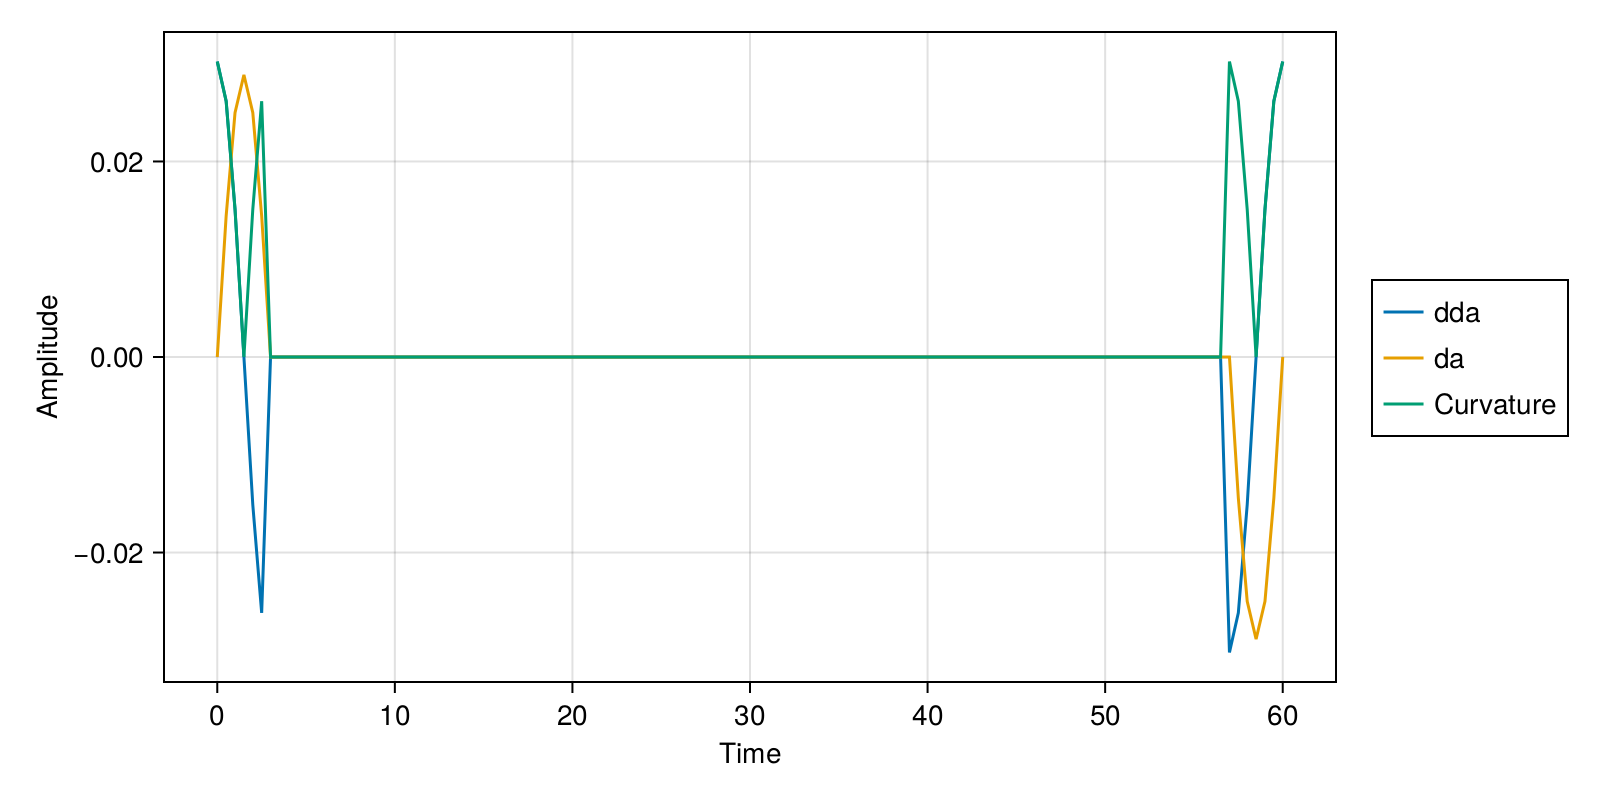

In [6]:
partial_flat_gaussian(t) = flat_gaussian(t, area=π, width=0.9, T=T, Δt=Δt)
result = compute_derivatives(partial_flat_gaussian, times)
c_f_t = [curvature(partial_flat_gaussian, t) for t in times]

f = Figure(size = (800, 400))
ax = f[1, 1] = Axis(f, xlabel = "Time", ylabel = "Amplitude")
for (k, v) in result
    if k == :a
        continue
    end
    lines!(ax, times, v, label=String(k))
end
lines!(ax, times, c_f_t, label="Curvature")
Legend(f[1, 2], ax)
f

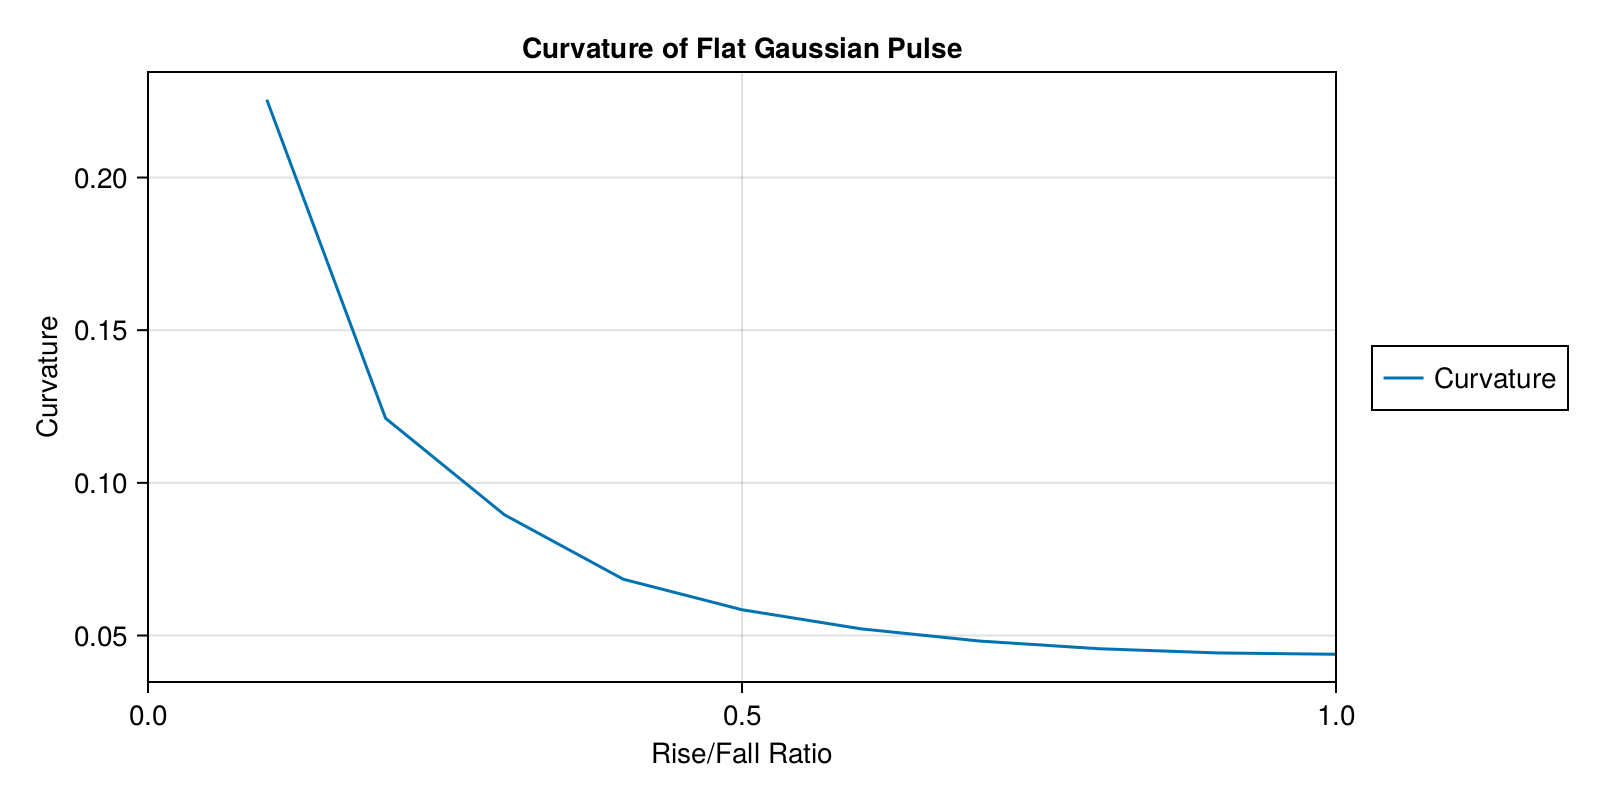

In [7]:
rs= range(0.1, 1.0, length=10)
κs = map(rs) do r
    total = 0.0
    for a in [π, 3π]
        partial_flat_gaussian(t) = flat_gaussian.(t, area=π, width=1 - r, T=T, Δt=Δt)
        total += trapezoid_rule([curvature(partial_flat_gaussian, t) for t in times], dx=Δt)
    end
    total
end

f = Figure(size=(800, 400))
ax = Axis(f[1,1], xlabel="Rise/Fall Ratio", ylabel="Curvature", title="Curvature of Flat Gaussian Pulse")
lines!(ax, rs, κs, label="Curvature")
Legend(f[1,2], ax)
xlims!(ax, 0.0, 1.0)
f

In [8]:
# Rotating frame Hamiltonians have 1/2 prefactor
qubit_system = QuantumSystem(zeros(2, 2), [kron_from_dict("X", H_ops) / 2])

H_control_names = ["XI", "IX"]
H_controls = [kron_from_dict(H, H_ops) / 2 for H in H_control_names]
system = QuantumSystem(zeros(4, 4), H_controls)

H_crosstalk = 0.01 * kron_from_dict("ZZ", H_ops)
crosstalk_system = QuantumSystem(H_crosstalk, H_controls)

U_goal = kron_from_dict("XX", H_ops)
Ũ⃗_goal = operator_to_iso_vec(U_goal)
X̃⃗_goal = operator_to_iso_vec(kron_from_dict("X", H_ops))
;

Test the simulations

In [9]:
for w in [0.0, 0.5, 1.0]
    as = stack([
        flat_gaussian.(times, area=π, width=w, T=T, Δt=Δt),
    ], dims=1)
    
    # Must use Δt or Δts (not times)
    Ũ⃗s = unitary_rollout(as, Δt, qubit_system)

    println("Fidelity for w=$w: ", unitary_fidelity(Ũ⃗s[:, end], X̃⃗_goal))
end

Fidelity for w=0.0: 1.0000000000000004
Fidelity for w=0.5: 1.0000000000000004
Fidelity for w=1.0: 0.9999999999999897


In [10]:
for w in [0.0, 0.5, 1.0]
    as = stack([
        flat_gaussian.(times, area=π, width=w, T=T, Δt=Δt),
        flat_gaussian.(times, area=3π, width=w, T=T, Δt=Δt)
    ], dims=1)

    Ũ⃗s = unitary_rollout(as, Δt, system)

    println("Fidelity for w=$w: ", unitary_fidelity(Ũ⃗s[:, end], Ũ⃗_goal))
end

Fidelity for w=0.0: 0.9999999999999996
Fidelity for w=0.5: 0.9999999999999964
Fidelity for w=1.0: 0.9999999999999986


In [11]:
for w in [0.0, 0.5, 1.0]
    as = stack([
        flat_gaussian.(times, area=π, width=w, T=T, Δt=Δt),
        flat_gaussian.(times, area=3π, width=w, T=T, Δt=Δt)
    ], dims=1)

    Ũ⃗s = unitary_rollout(as, Δt, crosstalk_system)

    println("Fidelity for w=$w: ", unitary_fidelity(Ũ⃗s[:, end], Ũ⃗_goal))
end

Fidelity for w=0.0: 0.970939873292094
Fidelity for w=0.5: 0.988791456565045
Fidelity for w=1.0: 0.9989899187261364


Test crosstalk and optimal control.

In [12]:
function loss(H_error::AbstractMatrix, Z::NamedTrajectory)
    Z⃗ = vec(Z.data)
    return InfidelityRobustnessObjective(H_error, Z).L(Z⃗, Z)
end

loss (generic function with 1 method)

In [13]:
ops = Options()
ops.recalc_y = "yes"
ops.recalc_y_feas_tol = 1e-2
ops.print_level = 4

# Need 1 extra step to include the final time (should change my definition of flat_gaussian)
prob = UnitarySmoothPulseProblem(
    system, U_goal, T+1, Δt;
    geodesic=true,
    timesteps_all_equal=true,
    free_time=false,
    hessian_approximation=true,
    pade_order=4,
    R=1e-3,
    R_dda=1.0,
    ipopt_options=ops
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB


applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a


applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(39) … MOI.VariableIndex(4523) MOI.VariableIndex(4561); MOI.VariableIndex(2) MOI.VariableIndex(40) … MOI.VariableIndex(4524) MOI.VariableIndex(4562); … ; MOI.VariableIndex(37) MOI.VariableIndex(75) … MOI.VariableIndex(4559) MOI.VariableIndex(4597); MOI.VariableIndex(38) MOI.VariableIndex(76) … MOI.VariableIndex(4560) MOI.VariableIndex(4598)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 4, 4), sparse(Int64[], Int64[], Float64[], 4, 4), SparseArrays.SparseMatrixCSC{Float64, Int64}[sparse([3, 4, 1, 2], [1, 2, 3, 4], [0.5, 0.5, 0.5, 0.5], 4, 4), sparse([2, 1, 4, 3], [1, 2, 3, 4], [0.5, 0.5, 0.5, 0.5], 4, 4)], SparseArrays.SparseMatrixCSC{Float64, Int64}[sparse(Int64[], Int64[], Float64[], 4, 4), sparse(Int64[], Int64[], Float64[], 4, 4)], sparse(Int64[], Int64[], Float64[], 8, 8), SparseArrays.SparseMatrixCSC{Float64, Int64}[sparse([7, 8, 5, 6, 3, 4, 1, 2], [1, 2, 3, 4

In [14]:
solve!(prob; max_iter=200)
println("Unitary fidelity: ", unitary_fidelity(prob))


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Total number of variables............................:     4562
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:     4320
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0




Number of Iterations....: 200

                                   (scaled)                 (unscaled)
Objective...............:   2.6373112420842172e-04    2.6373112420842172e-04
Dual infeasibility......:   2.3056132792485880e-03    2.3056132792485880e-03
Constraint violation....:   1.6679726102530879e-06    1.6679726102530879e-06
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   0.0000000000000000e+00    0.0000000000000000e+00
Overall NLP error.......:   2.3056132792485880e-03    2.3056132792485880e-03


Number of objective function evaluations             = 884
Number of objective gradient evaluations             = 201
Number of equality constraint evaluations            = 893
Number of inequality constraint evaluations          = 0
Number of equality constraint Jacobian evaluations   = 201
Number of inequality constraint Jacobian evaluations = 0
Number of Lagrangian Hessian evaluations             = 0
Total seconds in IPOPT    

In [15]:
function construct_trajectory(
        traj::NamedTrajectory,
        system::QuantumSystem,
        width::Real,
        areas::AbstractArray
    )
    T = traj.T
    Δt = traj.timestep
    @assert Δt isa Real "Time step must be a real number"

    times = range(0, T * Δt, length=T+1)
    clist = map(areas) do a
        compute_derivatives(t -> flat_gaussian(t, area=a, width=width, T=T, Δt=Δt), times)
    end

    cs = Dict(
        key => stack([c[key] for c ∈ clist], dims=1)
        for key in [:a, :da, :dda]
    )

    # NOTE: loss will use the rollout values obtained here
    components = (
        Ũ⃗ = unitary_rollout(cs[:a], Δt, system),
        a = cs[:a],
        da = cs[:da],
        dda = cs[:dda],
    )


    return NamedTrajectory(
        components;
        controls=(:dda,),
        timestep=Δt,
        bounds=traj.bounds,
        initial=traj.initial,
        final=traj.final,
        goal=traj.goal
    )
end

construct_trajectory (generic function with 1 method)

In [ ]:
# plot(construct_trajectory(prob.trajectory, crosstalk_system, 0.5, [π, 3π]))

The crosstalk measure itself is not very susceptible to whether you rollout with a model that has crosstalk or a model that does not. Logically, we would rollout without crosstalk because this is the cost term that we optimize.

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie /home/andy/.julia/packages/Makie/VRavR/src/scenes.jl:220


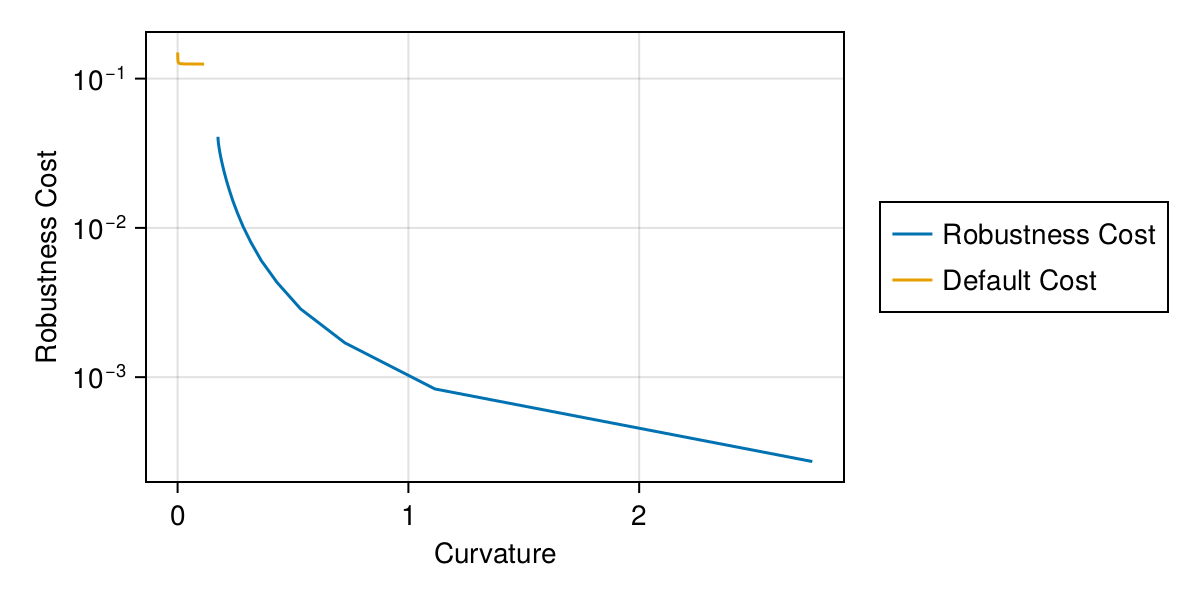

In [16]:
f = Figure(resolution=(600, 300))
ax = Axis(f[1,1], xlabel="Curvature", ylabel="Robustness Cost", yscale=log10)

ws = 0:.05:0.95
x = Float64[]
y = Float64[]
for w in ws
    traj = construct_trajectory(prob.trajectory, system, w, [π, 3π])
    push!(x, sum(abs.(traj[:dda])))
    push!(y, loss(H_crosstalk, traj))
end
lines!(ax, x, y, label="Robustness Cost")

x = Float64[]
y = Float64[]
for w in ws
    traj = construct_trajectory(prob.trajectory, system, w, [π, π])
    push!(x, maximum(abs.(traj[:dda])))
    push!(y, loss(H_crosstalk, traj))
end
lines!(ax, x, y, label="Default Cost")

# xlims!(0, 1)

Legend(f[1,2], ax)

f

In [41]:
# results = []

# ops = Options()
# ops.recalc_y = "yes"
# ops.recalc_y_feas_tol = 1e-2
# ops.print_level = 1

# previous_loss = Inf
# for bound in 10 .^ range(-3, 1, length=50)
#     traj = copy(prob.trajectory)
#     update_bound!(traj, :dda, bound)

#     objective = QuadraticRegularizer(:dda, traj, 1e-6)

#     rob_prob = UnitaryRobustnessProblem(
#         H_crosstalk,
#         traj,
#         prob.system,
#         objective,
#         prob.integrators,
#         AbstractConstraint[];
#         build_trajectory_constraints=true,
#         hessian_approximation=true,
#         pade_order=4,
#         ipopt_options=ops,
#     )
#     traj = copy(rob_prob.trajectory)
    
#     println("\nRegularization: $bound")
    
#     attempt = 1
#     current_loss = Inf
#     best_loss = Inf
#     while attempt <= 25
#         println("\tAttempt: ", attempt, " with loss: ", current_loss, " and previous loss: ", previous_loss)
#         if attempt > 20
#             # Try some big attempts
#             solve!(rob_prob; max_iter=100)
#         else
#             solve!(rob_prob; max_iter=30)
#         end
#         current_loss = loss(H_crosstalk, rob_prob.trajectory)
#         # In case you get stuck and run out of iterations, fall back to the best solution
#         if current_loss < best_loss
#             best_loss = current_loss
#             traj = copy(rob_prob.trajectory)
#         end
#         if current_loss < previous_loss || current_loss < 1e-5
#             break
#         end
#         attempt += 1
#     end
#     previous_loss = min(best_loss, previous_loss)

#     # ... don't save this value, bc technically not the best traj we saved
#     println("\tFidelity: ", unitary_fidelity(rob_prob))

#     entry = Dict(
#         :bound => bound,
#         :traj => copy(traj),
#         :y => loss(H_crosstalk, traj), 
#         :x => maximum(abs.(traj[:dda])),
#         :x1 => sum(abs.(traj[:dda]))
#     )
#     println("\tRobustness cost: ", entry[:y], "\n\tCurvature: ", entry[:x], "\n\tSum of curvature: ", entry[:x1])
#     println()

#     push!(results, entry)
end

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 0.001
	Attempt: 1 with loss: Inf and previous loss: Inf


	Fidelity: 0.9999060152050327
	Robustness cost: 0.03991434736127354
	Curvature: 0.0008742815260184727
	Sum of curvature: 0.15113788371601292

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 0.0012067926406393288
	Attempt: 1 with loss: Inf and previous loss: 0.03991434736127354


	Fidelity: 0.9999994334557998
	Robustness cost: 0.02376345582884989
	Curvature: 0.0010416538443197118
	Sum of curvature: 0.17145951048424485

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 0.0014563484775012444
	Attempt: 1 with loss: Inf and previous loss: 0.02376345582884989


	Attempt: 2 with loss: 0.10017337762960939 and previous loss: 0.02376345582884989


	Fidelity: 0.9999999996921178
	Robustness cost: 0.013132904058008503
	Curvature: 0.0012181101916381278
	Sum of curvature: 0.18671247321753387

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 0.0017575106248547913
	Attempt: 1 with loss: Inf and previous loss: 0.013132904058008503


	Fidelity: 0.9999996288791542
	Robustness cost: 0.00713728388203869
	Curvature: 0.0013885568612155752
	Sum of curvature: 0.1967574722280132

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 0.0021209508879201904
	Attempt: 1 with loss: Inf and previous loss: 0.00713728388203869


... (178 outputs left out)

	Fidelity: 0.9999884176713151
	Robustness cost: 2.9531523367199967e-7
	Curvature: 1.08699285555728
	Sum of curvature: 64.14740947656564

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 6.8664884500430015
	Attempt: 1 with loss: Inf and previous loss: 2.9531523367199967e-7


	Fidelity: 0.9999990728183372
	Robustness cost: 8.27250238814923e-7
	Curvature: 0.8811837333867515
	Sum of curvature: 66.35220439105558

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 8.286427728546844
	Attempt: 1 with loss: Inf and previous loss: 2.9531523367199967e-7


	Fidelity: 0.9999997545208881
	Robustness cost: 3.4489364507921844e-7
	Curvature: 0.4775907172593871
	Sum of curvature: 24.640896949954026

            memory estimate for stored jacobians: T * sizeof(∂f) = 121 * 7.968e-6 = 0.0009641280000000001 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda

Regularization: 10.0
	Attempt: 1 with loss: Inf and previous loss: 2.9531523367199967e-7


	Fidelity: 0.9999999974072753
	Robustness cost: 1.5954189191205992e-7
	Curvature: 0.6199720528183267
	Sum of curvature: 30.485133447499095



In [43]:
# save_object("../playground/robust_vs_curvature_solutions.jld2", results)

In [17]:
results = load_object("../playground/robust_vs_curvature_solutions.jld2");

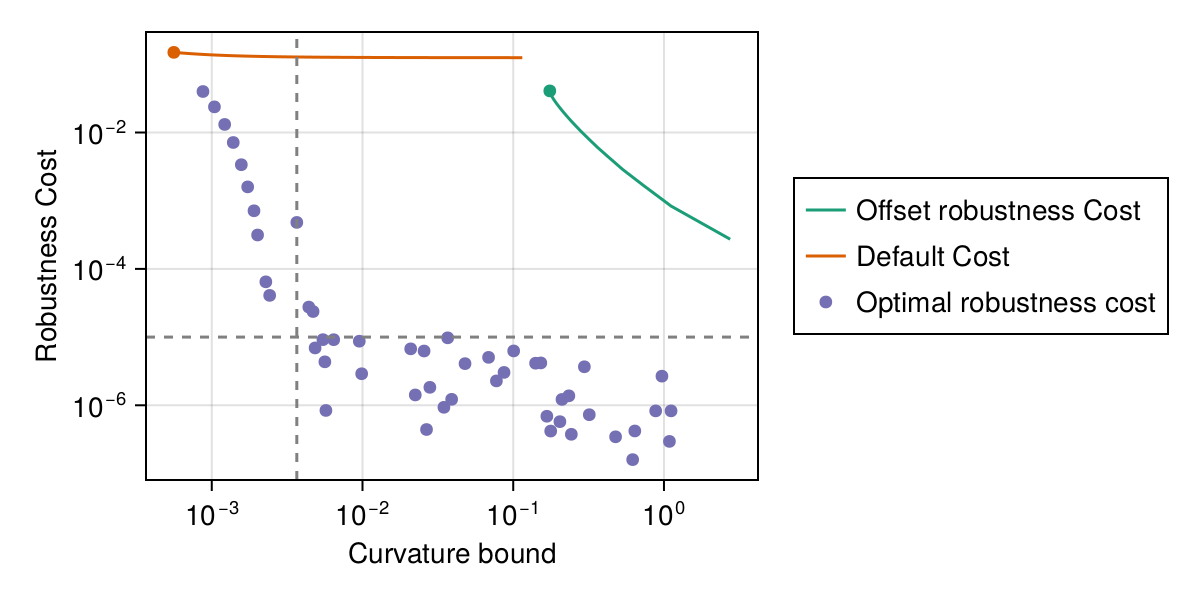

In [38]:
f = Figure(size=(600, 300))
ax = Axis(f[1,1], xlabel="Curvature bound", ylabel="Robustness Cost", xscale=log10, yscale=log10)


three_colorblind_palette = ["#1b9e77", "#d95f02", "#7570b3"]

ws = 0:.05:0.98
x = Float64[]
y = Float64[]
for w in ws
    traj = construct_trajectory(prob.trajectory, system, w, [π, 3π])
    push!(x, sum(abs.(traj[:dda])))
    push!(y, loss(H_crosstalk, traj))
end
lines!(ax, x, y, label="Offset robustness Cost", color=three_colorblind_palette[1])
scatter!(ax, x[1], y[1], color=three_colorblind_palette[1])

x = Float64[]
y = Float64[]
for w in ws
    traj = construct_trajectory(prob.trajectory, system, w, [π, π])
    push!(x, maximum(abs.(traj[:dda])))
    push!(y, loss(H_crosstalk, traj))
end
lines!(ax, x, y, label="Default Cost", color=three_colorblind_palette[2])
scatter!(ax, x[1], y[1], color=three_colorblind_palette[2])


# xlims!(0, 1)
rd = Dict(
    key => stack([c[key] for c ∈ results], dims=1)
    for key in [:x, :y]
)
ii = sortperm(rd[:x])
scatter!(ax, rd[:x][ii], rd[:y][ii], label="Optimal robustness cost", color=three_colorblind_palette[3])

# lines!(ax, [10^-3, 10^.5], [1e-5, 1e-5], color=:black, linestyle=:dash) #, label="Threshold")
hlines!(ax, [1e-5], color=:gray, linestyle=:dash)# label="Threshold")
vlines!(ax, [rd[:x][ii][11]], color=:gray, linestyle=:dash)# label="Threshold")

Legend(f[1,2], ax)

f

In [44]:
argmax(rd[:x] .=== rd[:x][ii][11])

9

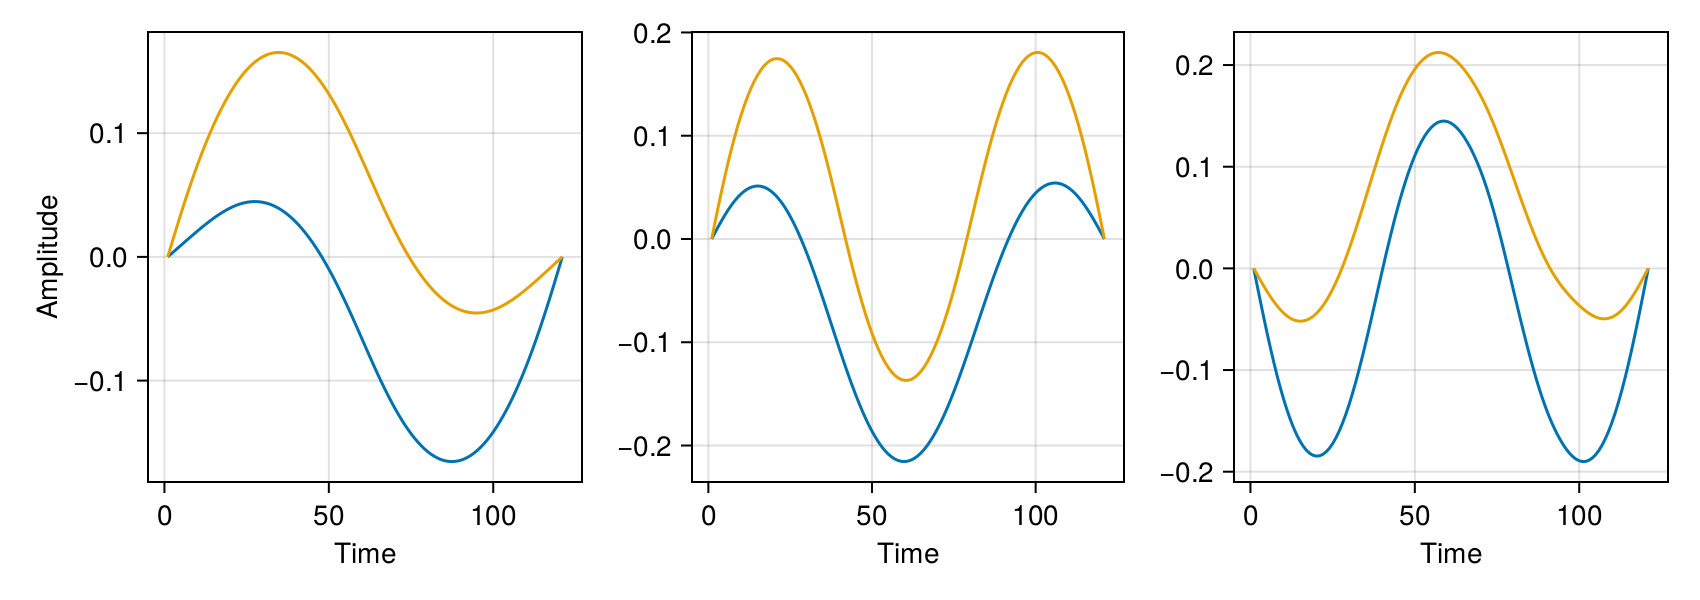

In [48]:
f = Figure(size=(850, 300))
ax = Axis(f[1,1], xlabel="Time", ylabel="Amplitude")
for a in eachrow(results[3][:traj][:a])
    lines!(ax, a)
end

ax = Axis(f[1,2], xlabel="Time") #ylabel="Amplitude")
for a in eachrow(results[9][:traj][:a])
    lines!(ax, a)
end

ax = Axis(f[1,3], xlabel="Time") #ylabel="Amplitude")
for a in eachrow(results[12][:traj][:a])
    lines!(ax, a)
end
f